# Life locations: what the extracted fields contain
The five Wikidata fields extracted by `26_extract_life_locations.py`, read as they were extracted: most frequent values, dates and precisions.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl

sys.path.insert(0, '../../../notebooks/notebooks_analysis')
from style import *

apply_style()

FOLDER = Path('../../../data/raw_data_from_wikidata/wikidata_extraction_scripts_v2/life_locations')
FIELDS = {'work_location': 'P937', 'residence': 'P551', 'employer': 'P108', 'educated_at': 'P69', 'position_held': 'P39'}
TOP = 20
PRECISIONS = {6: 'millennium', 7: 'century', 8: 'decade', 9: 'year', 10: 'month', 11: 'day'}

pl.Config.set_tbl_rows(TOP)
pl.Config.set_fmt_str_lengths(60)
pl.Config.set_tbl_width_chars(200)

polars.config.Config

## Data
One row per statement: the individual, the target, the rank, and the year and precision of each qualifier (start P580, end P582, point in time P585). Targets carry their English label and whether they can be placed: own coordinates (P625), a location with coordinates (P131 / P159 / P276), or a jurisdiction with coordinates (P1001).

In [2]:
def year(date):
    if date is None:
        return None
    text = date['time']
    return int(text[: text.index('-', 1)])


def load_statements(field, pid):
    data = json.loads((FOLDER / f'{field}_{pid}_statements.json').read_text())
    columns = {name: [] for name in ['qid', 'target', 'rank', 'start_year', 'start_precision', 'end_year', 'end_precision', 'point_in_time_year', 'point_in_time_precision']}
    for qid, statements in data.items():
        for statement in statements:
            columns['qid'].append(qid)
            columns['target'].append(statement['target'])
            columns['rank'].append(statement['rank'])
            for qualifier in ['start', 'end', 'point_in_time']:
                columns[f'{qualifier}_year'].append(year(statement[qualifier]))
                columns[f'{qualifier}_precision'].append(statement[qualifier]['precision'] if statement[qualifier] else None)
    return pl.DataFrame(columns).with_columns(field=pl.lit(field))


statements = pl.concat([load_statements(field, pid) for field, pid in FIELDS.items()])
statements = statements.with_columns(dated=pl.any_horizontal(pl.col('start_year', 'end_year', 'point_in_time_year').is_not_null()))
print(f'{statements.height:,} statements')
statements.sample(5, seed=0)

9,120,087 statements


qid,target,rank,start_year,start_precision,end_year,end_precision,point_in_time_year,point_in_time_precision,field,dated
str,str,str,i64,i64,i64,i64,i64,i64,str,bool
"""Q87407825""","""Q482659""","""normal""",2007,11,null,null,null,null,"""employer""",true
"""Q967052""","""Q28729082""","""normal""",1909,9,null,null,null,null,"""employer""",true
"""Q91711807""","""Q30273140""","""normal""",null,null,null,null,null,null,"""employer""",false
"""Q11724499""","""Q270""","""normal""",null,null,null,null,null,null,"""work_location""",false
"""Q131381571""","""Q1056123""","""normal""",null,null,2014,9,null,null,"""educated_at""",true


In [3]:
raw_targets = json.loads((FOLDER / 'targets.json').read_text())
targets = pl.DataFrame({
    'target': list(raw_targets),
    'label': [t['label_en'] for t in raw_targets.values()],
    'own_coordinates': [t['coordinates'] is not None for t in raw_targets.values()],
    'location_coordinates': [any(c for c in t['located_in'].values()) for t in raw_targets.values()],
    'jurisdiction_coordinates': [any(c for c in t['jurisdiction'].values()) for t in raw_targets.values()],
})
assert targets['target'].is_unique
missing = statements.join(targets, on='target', how='anti').height
print(f'{targets.height:,} targets; statements whose target is missing from targets.json: {missing:,}')
targets.sample(5, seed=0)

446,485 targets; statements whose target is missing from targets.json: 0


target,label,own_coordinates,location_coordinates,jurisdiction_coordinates
str,str,bool,bool,bool
"""Q1916210""","""Cárdenas""",true,true,false
"""Q26691502""","""mayor of Pechina""",false,false,true
"""Q23836176""","""Deputy Minister of the Economy""",false,false,true
"""Q101021853""","""University of Texas M D Anderson Cancer Center Department of…",false,true,false
"""Q3709329""","""Hammond""",true,true,false


## Overview
Individuals with at least one statement, statements, distinct targets, and the share of statements carrying at least one date.

In [4]:
overview = (
    statements.group_by('field')
    .agg(
        pl.col('qid').n_unique().alias('individuals'),
        pl.len().alias('statements'),
        pl.col('target').n_unique().alias('distinct_targets'),
        (100 * pl.col('dated').mean()).round(1).alias('dated_%'),
        (100 * (pl.col('rank') == 'deprecated').mean()).round(2).alias('deprecated_%'),
    )
    .sort(pl.col('field').cast(pl.Enum(list(FIELDS))))
)
overview

field,individuals,statements,distinct_targets,dated_%,deprecated_%
str,u32,u32,u32,f64,f64
"""work_location""",452348,587882,44063,10.1,0.03
"""residence""",355674,406849,58581,37.5,0.09
"""employer""",1558389,2555986,162462,58.4,0.03
"""educated_at""",2484659,3620716,91030,37.0,0.03
"""position_held""",979507,1948654,145963,66.0,0.08


## Date precision
Share of each precision among the stated dates of each field, all three qualifiers together.

In [5]:
precision = (
    pl.concat([
        statements.select('field', pl.col(f'{qualifier}_precision').alias('precision'))
        for qualifier in ['start', 'end', 'point_in_time']
    ])
    .drop_nulls('precision')
    .with_columns(pl.col('precision').replace_strict(PRECISIONS, default='other'))
    .group_by('field', 'precision').len()
    .with_columns((100 * pl.col('len') / pl.col('len').sum().over('field')).round(1).alias('share'))
    .pivot(on='precision', index='field', values='share')
    .fill_null(0)
    .sort(pl.col('field').cast(pl.Enum(list(FIELDS))))
)
precision.select('field', *[p for p in ['day', 'month', 'year', 'decade', 'century', 'millennium', 'other'] if p in precision.columns])

field,day,month,year,decade,century,millennium,other
str,f64,f64,f64,f64,f64,f64,f64
"""work_location""",4.3,2.1,93.3,0.3,0.0,0.0,0.0
"""residence""",60.2,2.9,35.6,0.8,0.5,0.0,0.0
"""employer""",57.3,16.1,26.6,0.1,0.0,0.0,0.0
"""educated_at""",45.1,16.7,38.2,0.0,0.0,0.0,0.0
"""position_held""",69.7,2.6,27.5,0.1,0.0,0.0,0.0


## Top values
For each field, the targets held by the most individuals, with whether they can be placed on a map.

In [6]:
def top_targets(field):
    held = statements.filter(pl.col('field') == field)
    individuals = held['qid'].n_unique()
    return (
        held.group_by('target')
        .agg(pl.col('qid').n_unique().alias('individuals'), pl.col('dated').mean().alias('dated'))
        .sort('individuals', descending=True)
        .head(TOP)
        .join(targets, on='target', how='left')
        .select(
            'target', 'label', 'individuals',
            (100 * pl.col('individuals') / individuals).round(2).alias('share_of_field_%'),
            (100 * pl.col('dated')).round(0).alias('dated_%'),
            'own_coordinates', 'location_coordinates', 'jurisdiction_coordinates',
        )
    )


def plot_top(table):
    fig, ax = plt.subplots(figsize=(12, 8))
    labels = [f'{label or target} ({target})' for label, target in zip(table['label'], table['target'])]
    positions = range(table.height)[::-1]
    ax.barh(positions, table['individuals'], color=MAIN_COLOR)
    ax.set_yticks(positions, labels)
    ax.xaxis.set_major_formatter(THOUSANDS)
    ax.set_xlabel('Individuals', fontsize=16)
    ax.tick_params(labelsize=13)
    ax.grid(axis='y', visible=False)
    plt.tight_layout()
    plt.show()

### Work location (P937)

In [7]:
work_location_top = top_targets('work_location')
work_location_top

target,label,individuals,share_of_field_%,dated_%,own_coordinates,location_coordinates,jurisdiction_coordinates
str,str,u32,f64,f64,bool,bool,bool
"""Q90""","""Paris""",23710,5.24,14.0,true,true,false
"""Q84""","""London""",18206,4.02,8.0,true,true,false
"""Q64""","""Berlin""",16248,3.59,6.0,true,true,false
"""Q61""","""Washington, D.C.""",13140,2.9,1.0,true,true,false
"""Q727""","""Amsterdam""",10554,2.33,65.0,true,true,false
"""Q220""","""Rome""",9990,2.21,17.0,true,true,false
"""Q1741""","""Vienna""",8426,1.86,7.0,true,true,false
"""Q1726""","""Munich""",8388,1.85,6.0,true,true,false
"""Q1715""","""Hanover""",7762,1.72,1.0,true,true,false


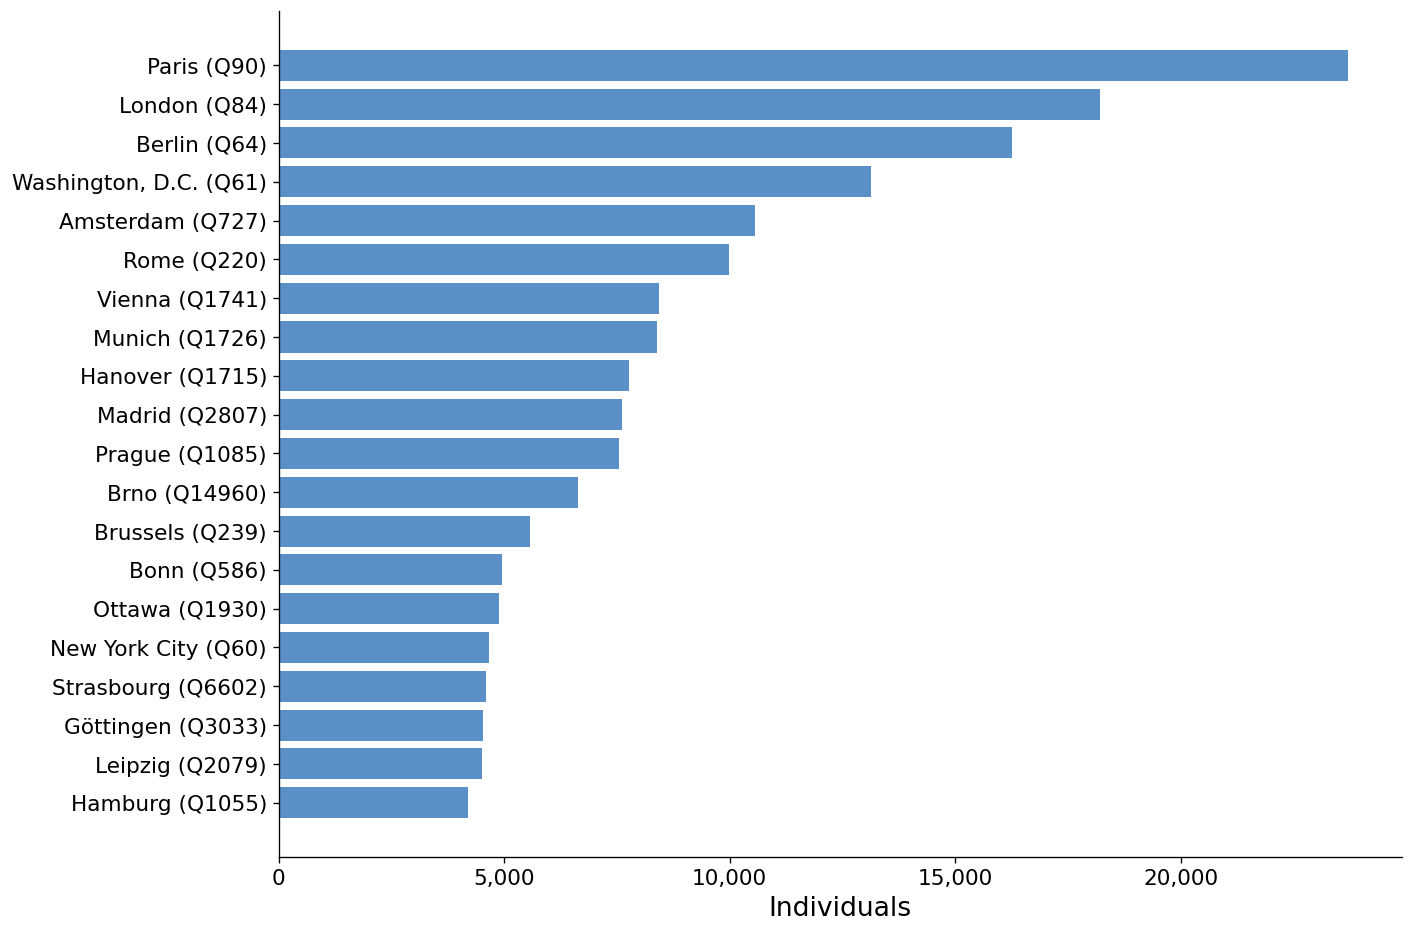

In [8]:
plot_top(work_location_top)

### Residence (P551)

In [9]:
residence_top = top_targets('residence')
residence_top

target,label,individuals,share_of_field_%,dated_%,own_coordinates,location_coordinates,jurisdiction_coordinates
str,str,u32,f64,f64,bool,bool,bool
"""Q1741""","""Vienna""",13775,3.87,49.0,true,true,false
"""Q771""","""Massachusetts""",8668,2.44,1.0,true,true,false
"""Q14960""","""Brno""",8372,2.35,94.0,true,true,false
"""Q12046812""","""Praha XII""",8040,2.26,99.0,true,true,false
"""Q12046801""","""Praha I""",6663,1.87,99.0,true,true,false
"""Q12046802""","""Praha II""",6471,1.82,99.0,true,true,false
"""Q60""","""New York City""",3524,0.99,14.0,true,true,false
"""Q65""","""Los Angeles""",3245,0.91,8.0,true,true,false
"""Q90""","""Paris""",2684,0.75,27.0,true,true,false


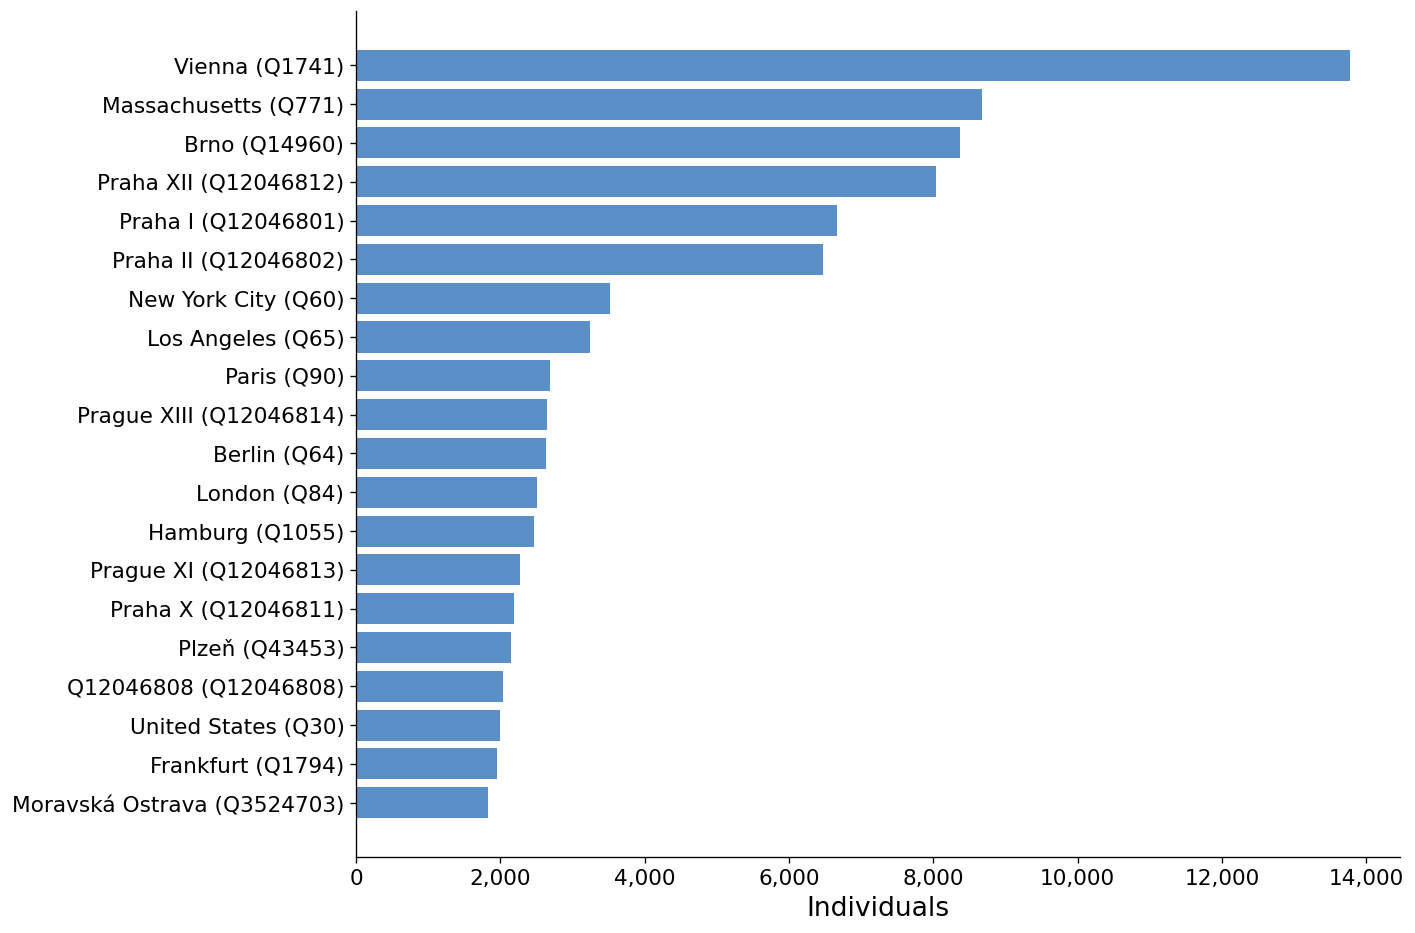

In [10]:
plot_top(residence_top)

### Employer (P108)

In [11]:
employer_top = top_targets('employer')
employer_top

target,label,individuals,share_of_field_%,dated_%,own_coordinates,location_coordinates,jurisdiction_coordinates
str,str,u32,f64,f64,bool,bool,bool
"""Q34433""","""University of Oxford""",8440,0.54,56.0,true,true,false
"""Q13371""","""Harvard University""",7505,0.48,38.0,true,true,false
"""Q41506""","""Stanford University""",7486,0.48,51.0,true,true,false
"""Q35794""","""University of Cambridge""",6938,0.45,71.0,true,true,false
"""Q230492""","""University of Michigan""",6886,0.44,51.0,true,true,false
"""Q193196""","""University College London""",6458,0.41,58.0,true,true,false
"""Q29052""","""Vanderbilt University""",6241,0.4,21.0,true,true,false
"""Q168756""","""University of California, Berkeley""",5958,0.38,50.0,true,true,false
"""Q7842""","""University of Tokyo""",5876,0.38,38.0,true,true,false


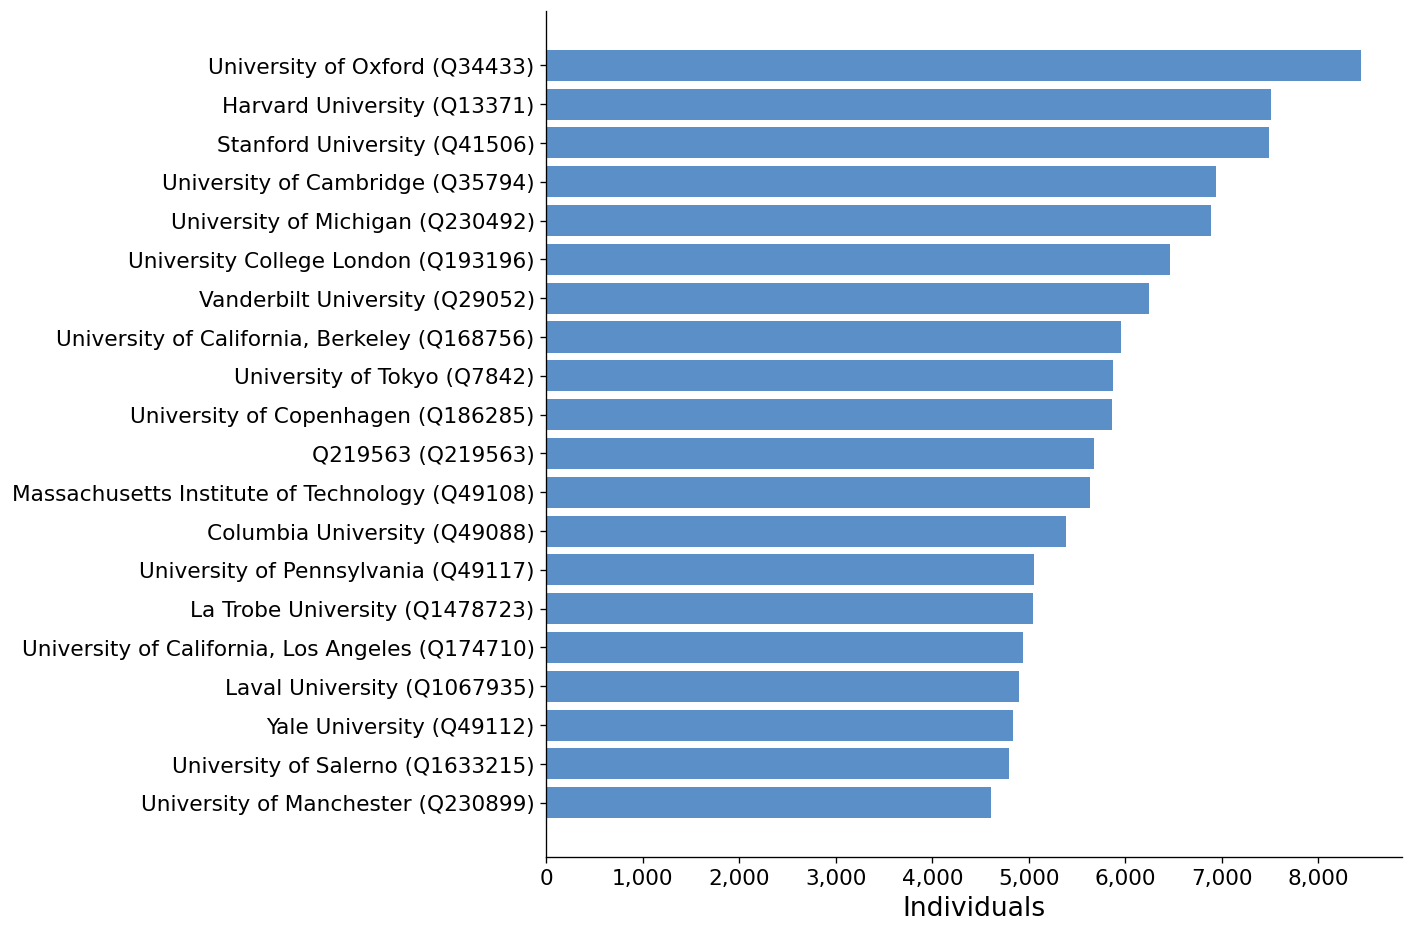

In [12]:
plot_top(employer_top)

### Educated at (P69)

In [13]:
educated_at_top = top_targets('educated_at')
educated_at_top

target,label,individuals,share_of_field_%,dated_%,own_coordinates,location_coordinates,jurisdiction_coordinates
str,str,u32,f64,f64,bool,bool,bool
"""Q13371""","""Harvard University""",25084,1.01,23.0,true,true,false
"""Q168756""","""University of California, Berkeley""",18550,0.75,37.0,true,true,false
"""Q41506""","""Stanford University""",17237,0.69,43.0,true,true,false
"""Q219563""",null,16907,0.68,65.0,true,true,false
"""Q7842""","""University of Tokyo""",15627,0.63,17.0,true,true,false
"""Q230492""","""University of Michigan""",15452,0.62,36.0,true,true,false
"""Q28024477""","""Imperial University of Dorpat""",15128,0.61,1.0,false,true,false
"""Q49088""","""Columbia University""",15120,0.61,26.0,true,true,false
"""Q49108""","""Massachusetts Institute of Technology""",14229,0.57,36.0,true,true,false


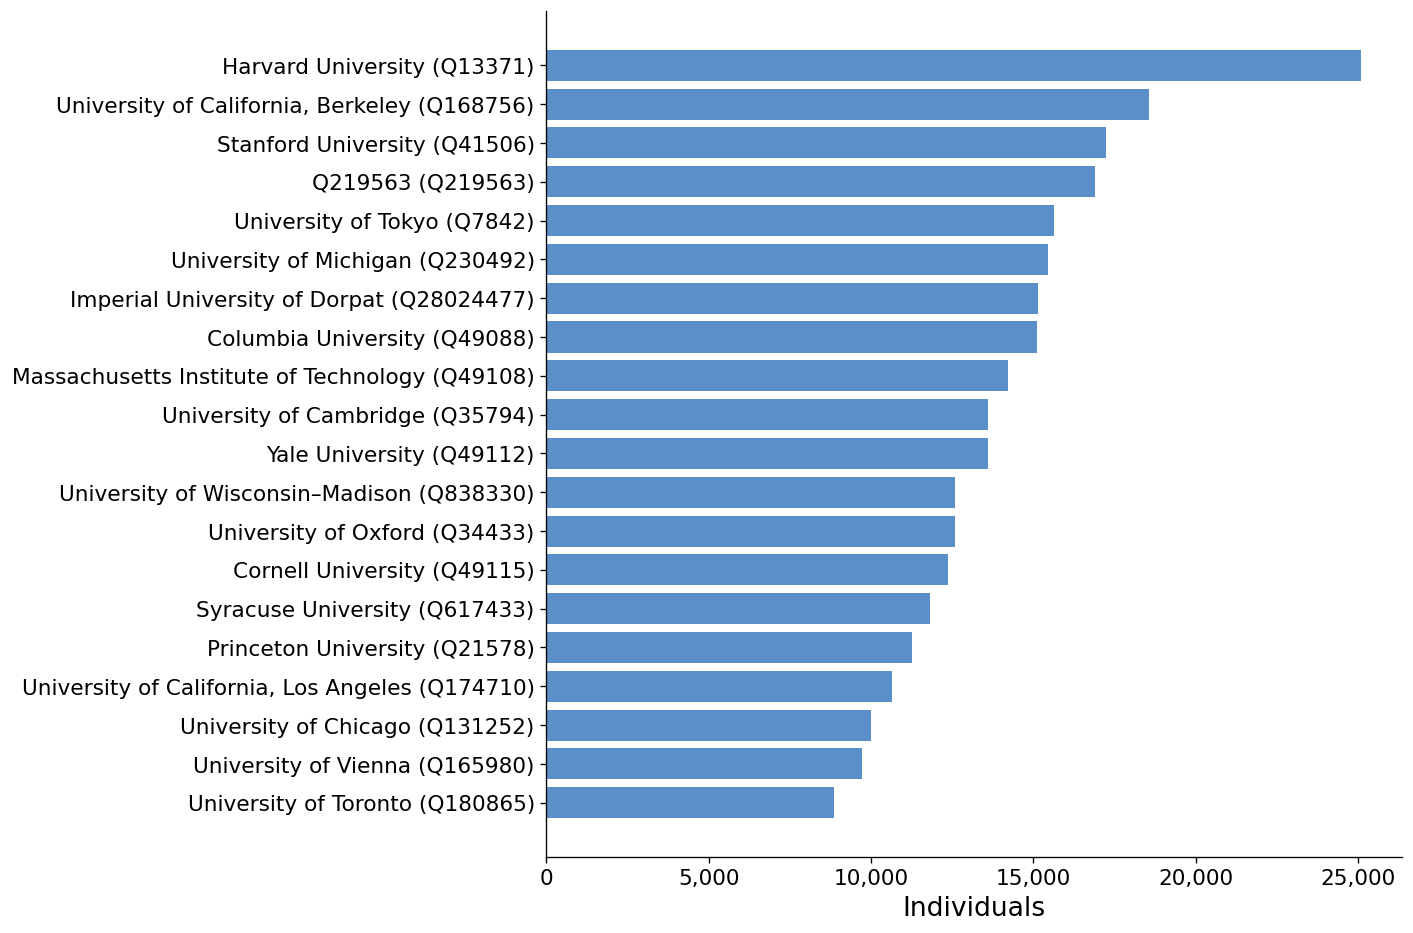

In [14]:
plot_top(educated_at_top)

### Position held (P39)

In [15]:
position_held_top = top_targets('position_held')
position_held_top

target,label,individuals,share_of_field_%,dated_%,own_coordinates,location_coordinates,jurisdiction_coordinates
str,str,u32,f64,f64,bool,bool,bool
"""Q1144278""","""diocesan bishop""",17479,1.78,99.0,false,false,false
"""Q30185""","""mayor""",15139,1.55,36.0,false,false,false
"""Q18694248""","""municipal councillor in Finland""",13742,1.4,0.0,false,false,false
"""Q18018860""","""Member of Parliament in the Parliament of England""",12705,1.3,2.0,false,false,true
"""Q13218630""","""United States representative""",11286,1.15,66.0,false,false,true
"""Q948657""","""titular bishop""",10879,1.11,99.0,false,false,false
"""Q1255921""","""president""",9835,1.0,78.0,false,false,false
"""Q83307""","""minister""",9432,0.96,3.0,false,false,false
"""Q140686""","""chairperson""",9342,0.95,75.0,false,false,false


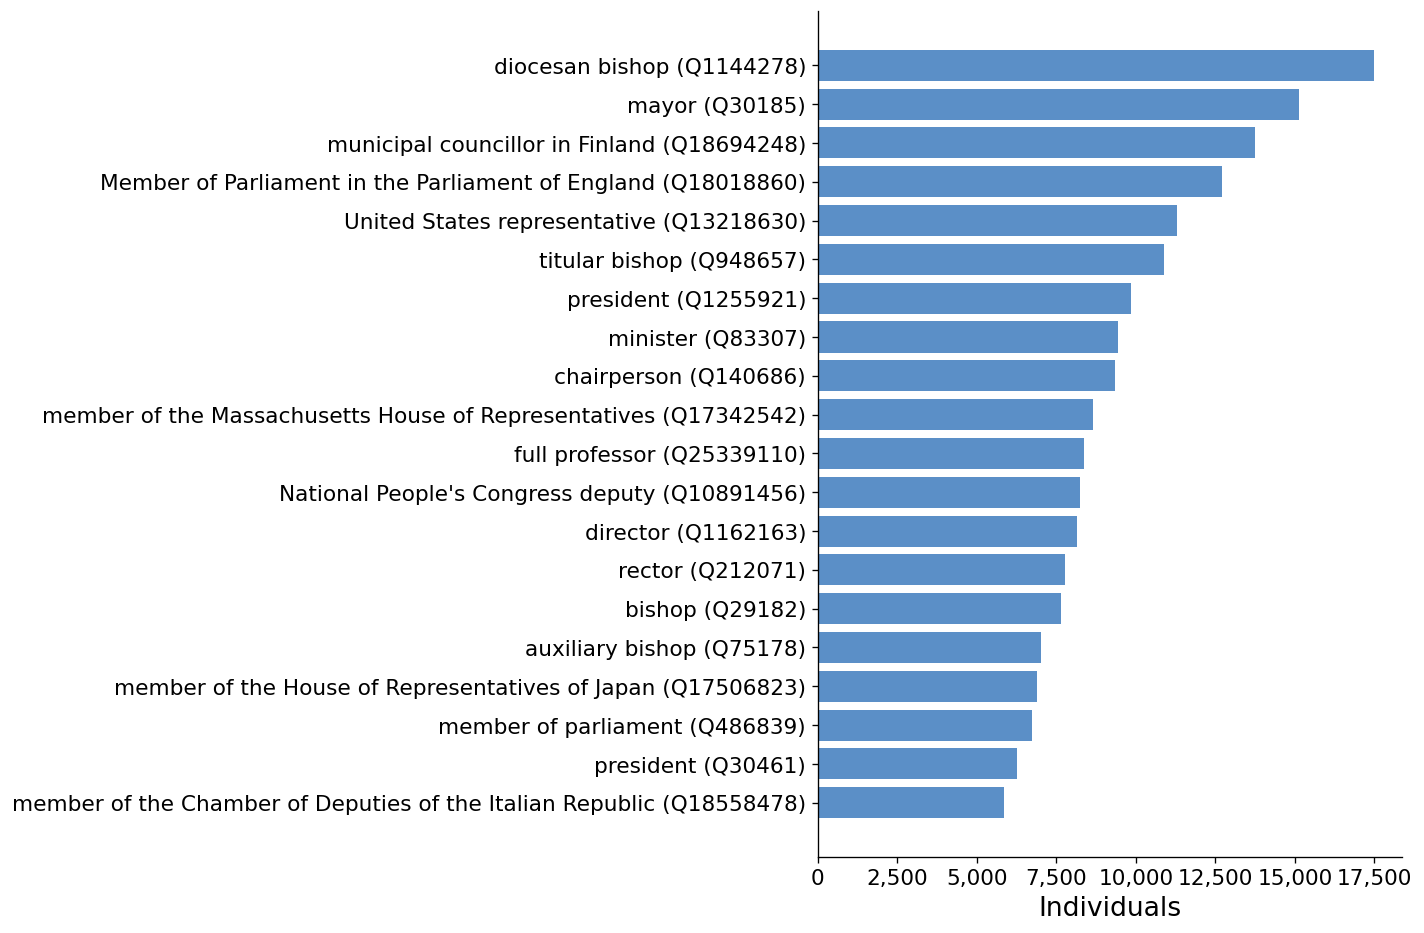

In [16]:
plot_top(position_held_top)